<a href="https://colab.research.google.com/github/madhavakirthickj2025cse-lab/FDS-Lab-Experiments/blob/main/exp_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 5 rows:
   Roll_No  Student Department  Marks  Performance  Year
0      201    Manoj         IT     78           82     1
1      202   Anitha        CSE     88           90     2
2      203   Suresh        EEE     91           93     3
3      204    Meena        ECE     74           76     1
4      205  Karthik        CSE     83           86     2

Missing values:
Roll_No        0
Student        0
Department     0
Marks          0
Performance    0
Year           0
dtype: int64

Summary Statistics:
         Roll_No      Marks  Performance      Year
count    8.00000   8.000000     8.000000  8.000000
mean   204.50000  84.375000    86.750000  2.500000
std      2.44949   7.190023     6.158618  1.195229
min    201.00000  74.000000    76.000000  1.000000
25%    202.75000  79.500000    83.500000  1.750000
50%    204.50000  84.000000    87.000000  2.500000
75%    206.25000  88.750000    90.750000  3.250000
max    208.00000  96.000000    95.000000  4.000000

Department Summary:
  Departmen

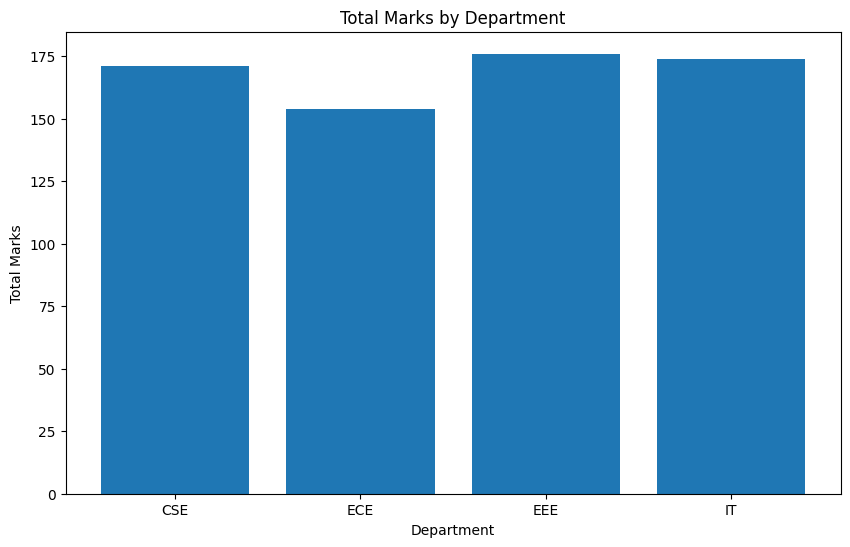

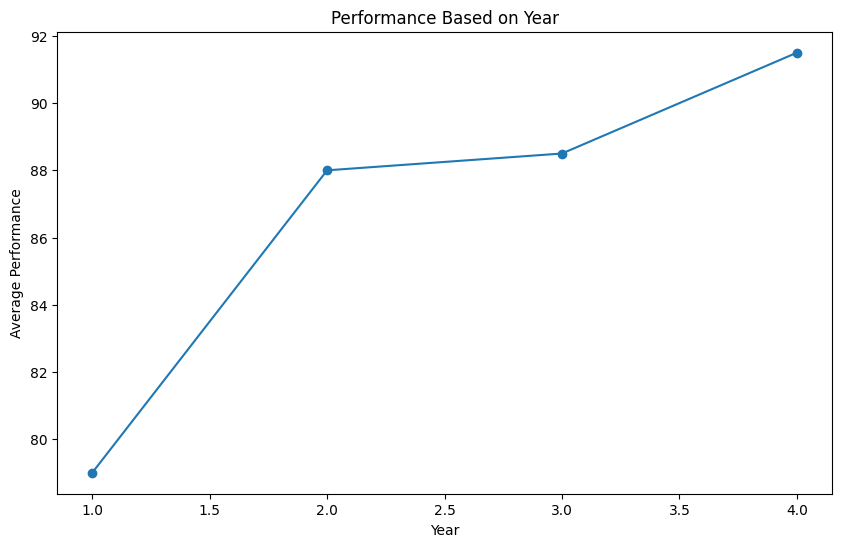


Pivot Table:
Year           1     2     3     4
Department                        
CSE          0.0  88.0   0.0   0.0
ECE         76.0   0.0  84.0   0.0
EEE          0.0   0.0  93.0  88.0
IT          82.0   0.0   0.0  95.0

Correlation Matrix:
              Roll_No     Marks  Performance      Year
Roll_No      1.000000  0.133838     0.132578  0.731925
Marks        0.133838  1.000000     0.983178  0.723119
Performance  0.132578  0.983178     1.000000  0.737482
Year         0.731925  0.723119     0.737482  1.000000


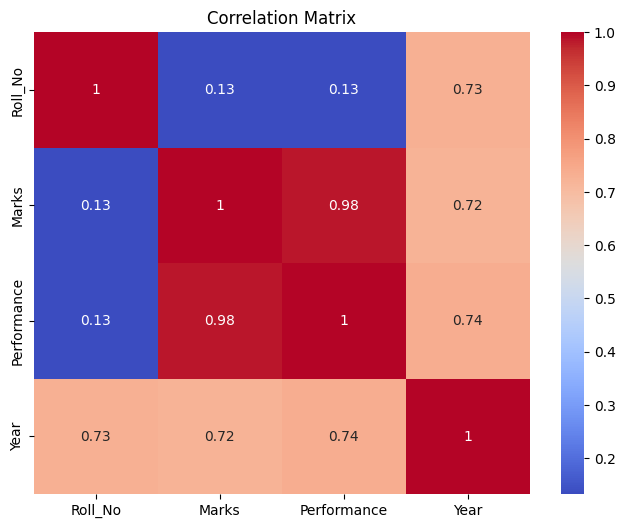

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    'Roll_No': [201, 202, 203, 204, 205, 206, 207, 208],
    'Student': ['Manoj', 'Anitha', 'Suresh', 'Meena',
                'Karthik', 'Pooja', 'Naveen', 'Lakshmi'],
    'Department': ['IT', 'CSE', 'EEE', 'ECE',
                   'CSE', 'IT', 'ECE', 'EEE'],
    'Marks': [78, 88, 91, 74, 83, 96, 80, 85],
    'Performance': [82, 90, 93, 76, 86, 95, 84, 88],
    'Year': [1, 2, 3, 1, 2, 4, 3, 4]
}

df = pd.DataFrame(data)

print("First 5 rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

df['Marks'] = df['Marks'].fillna(df['Marks'].mean())

df.dropna(
    subset=['Student', 'Department', 'Performance'],
    inplace=True
)

print("\nSummary Statistics:")
print(df.describe())

department_summary = df.groupby('Department').agg({
    'Marks': 'sum',
    'Performance': 'mean'
}).reset_index()

print("\nDepartment Summary:")
print(department_summary)

plt.figure(figsize=(10, 6))
plt.bar(department_summary['Department'],
        department_summary['Marks'])
plt.xlabel('Department')
plt.ylabel('Total Marks')
plt.title('Total Marks by Department')
plt.show()

performance_over_time = df.groupby(
    'Year'
)['Performance'].mean().reset_index()

plt.figure(figsize=(10, 6))
plt.plot(performance_over_time['Year'],
         performance_over_time['Performance'],
         marker='o')
plt.xlabel('Year')
plt.ylabel('Average Performance')
plt.title('Performance Based on Year')
plt.show()

pivot_table = df.pivot_table(
    values='Performance',
    index='Department',
    columns='Year',
    aggfunc='mean',
    fill_value=0
)

print("\nPivot Table:")
print(pivot_table)

correlation_matrix = df.corr(numeric_only=True)

print("\nCorrelation Matrix:")
print(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()